# Example #4: Embedding impedance from HFSS

The previous example recovered the embedding impedance of an SIS mixer from its pumped I-V curve. This impedance can also be calculated from an electromagnetic simulation of the RF circuit. This notebook uses the ``qmix.network`` module to read the S-parameters of the 230 GHz mixer from HFSS, to calculate the embedding impedance seen by the junction, and to compare it with the impedances recovered from measurements over an LO sweep from 214 to 255 GHz. The impedances are then used for the sideband impedances in the noise model of the mixer (``PumpedData.mixer_noise``).

The data are from the same device as in Example #3 (device #5.6 from Garrett, 2018). The example data are in ``example-data/``:

- ``hfss/tuner.s3p``: the tuning circuit (HFSS). Port 1 is the junction (a lumped port), port 2 connects to the finline, and port 3 is the IF output.
- ``hfss/finline.s2p``: the finline transition from the waveguide (HFSS). Port 1 is the waveguide, and port 2 connects to the tuning circuit.
- ``dciv.csv``, ``dcif.csv``: the unpumped DC I-V curve and IF power (as in Example #3).
- ``lo-sweep/fXXX.X_iv.csv``: pumped I-V curves at 23 LO frequencies.

In [1]:
%matplotlib inline

import contextlib
import io
import glob
import os

import numpy as np
import matplotlib.pyplot as plt

import qmix

# https://github.com/garrettj403/SciencePlots
import scienceplots
plt.style.use(['science', 'notebook'])

## Reading the S-parameters

``read_touchstone`` reads Touchstone files. These files were exported from HFSS without renormalizing the ports, so the reference impedance of each port is its HFSS port impedance, which is listed for every frequency in the comments of the file (``! Port Impedance``). ``read_touchstone`` uses these when the option line doesn't give a reference impedance.

In [2]:
from qmix.network import read_touchstone, embedding_impedance

tuner = read_touchstone('example-data/hfss/tuner.s3p')
finline = read_touchstone('example-data/hfss/finline.s2p')

print("Tuner:   {} ports, {:.1f} to {:.1f} GHz".format(tuner.num_ports, tuner.freq[0] / 1e9, tuner.freq[-1] / 1e9))
print("Finline: {} ports, {:.1f} to {:.1f} GHz".format(finline.num_ports, finline.freq[0] / 1e9, finline.freq[-1] / 1e9))
print("\nPort impedances at 230 GHz (ohms):")
print("  tuner:  ", np.round(tuner.interpolate([230e9]).z0[0], 1))
print("  finline:", np.round(finline.interpolate([230e9]).z0[0], 1))

Tuner:   3 ports, 0.1 to 300.1 GHz
Finline: 2 ports, 0.1 to 300.1 GHz

Port impedances at 230 GHz (ohms):
  tuner:   [13.3+0.j 58.8-0.j 22.4-0.j]
  finline: [288.4+0.j  60.7-0.j]


The waveguide port of the finline has an impedance of ~290 ohms, the mode impedance of the waveguide.

**Note:** Touchstone files are often renormalized to 50 ohms. In that case, the waveguide port must be terminated in its own mode impedance, not in 50 ohms. Otherwise, the mismatch at the waveguide port creates ripples in the embedding impedance that aren't there in the real mixer.

## Connecting the networks

``Network.connect`` connects port 2 of the tuner to port 2 of the finline. The ports of the result are the remaining ports of the tuner, followed by the remaining ports of the finline: port 1 is the junction, port 2 the IF, and port 3 the waveguide.

In [3]:
rf = tuner.connect(2, finline, 2)
print("RF circuit: {} ports".format(rf.num_ports))

RF circuit: 3 ports


## The embedding impedance

``embedding_impedance`` calculates the impedance seen at port 1, with the junction capacitance in parallel. Ports that are not terminated are matched to their reference impedance, so the waveguide (port 3) sees a matched load. Here, the IF port (port 2) is terminated by 50 ohms. The result is a function of frequency (in Hz) that returns the impedance in ohms.

The nominal capacitance of the junction is the specific capacitance (80 fF/um^2) times the area (1.5 um^2).

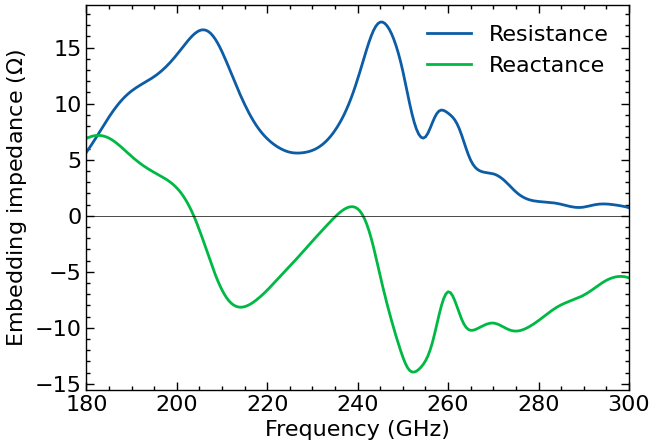

In [4]:
cap_nominal = 80e-15 * 1.5  # F

z_nominal = embedding_impedance(rf, 1, cap=cap_nominal, terminations={2: 50.})

f = np.linspace(180e9, 300e9, 241)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(f / 1e9, z_nominal(f).real, label='Resistance')
ax.plot(f / 1e9, z_nominal(f).imag, label='Reactance')
ax.axhline(0, c='k', lw=0.5)
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel(r'Embedding impedance ($\Omega$)')
ax.set_xlim(180, 300)
ax.legend();

## Comparing with the recovered impedances

We will now recover the embedding impedance from the pumped I-V curve at each LO frequency, as in Example #3.

In [5]:
params = dict(delimiter = ',',           # CSV files
              usecols = (0, 1),
              skip_header = 1,
              v_fmt = 'mV',              # units
              i_fmt = 'mA',
              area = 1.5,                # junction area in um^2
              filter_data = True,        # Savitzky-Golay filter
              filter_nwind = 21,
              verbose = False)


def load(filename):
    """Load a CSV file (bias voltage in mV, current in mA or IF power)."""
    return np.genfromtxt(filename, delimiter=',', skip_header=1)


def quiet():
    """Hide the printout of the impedance recovery."""
    return contextlib.redirect_stdout(io.StringIO())

In [6]:
with quiet():
    dciv = qmix.exp.DCData(load('example-data/dciv.csv'), load('example-data/dcif.csv'), **params)
print("Rn = {:.2f} ohms, Vgap = {:.3f} mV".format(dciv.rn, dciv.vgap * 1e3))

freq, zt, good = [], [], []
for filename in sorted(glob.glob('example-data/lo-sweep/f*_iv.csv')):
    f_lo = float(os.path.basename(filename)[1:-7])  # e.g., f230.2_iv.csv
    with quiet():
        pump = qmix.exp.PumpedData(load(filename), dciv, freq=f_lo, analyze_if=False, **params)
    freq.append(f_lo)
    zt.append(pump.zt)          # normalized to Rn
    good.append(pump.fit_good)  # was the impedance recovery successful?
freq, zt, good = np.array(freq), np.array(zt), np.array(good)

print("f (GHz)   recovered zt (Rn)")
for f_lo, z, g in zip(freq, zt, good):
    print("{:6.1f}    {:5.2f}{:+5.2f}j  {}".format(f_lo, z.real, z.imag, '' if g else '(bad fit)'))

Rn = 14.22 ohms, Vgap = 2.717 mV
f (GHz)   recovered zt (Rn)
 214.2     0.42-0.66j  
 215.7     0.36-0.48j  
 217.8     0.30-0.53j  
 220.1     0.31-0.51j  
 220.2     0.31-0.58j  
 221.8     0.39-0.57j  
 223.2     0.27-0.46j  
 225.9     0.24-0.30j  
 226.6     0.30-0.26j  
 228.3     0.23-0.11j  
 230.2     0.47-0.32j  
 230.8     0.43-0.34j  
 232.8     0.39-0.29j  
 235.1     0.42-0.27j  (bad fit)
 236.0     0.36-0.21j  (bad fit)
 238.4     0.51-0.36j  (bad fit)
 240.0     0.28-1.00j  (bad fit)
 240.7     0.45-0.57j  (bad fit)
 244.6     0.05-1.00j  (bad fit)
 245.6     0.00-0.91j  (bad fit)
 249.6     0.22-1.00j  (bad fit)
 252.2     0.23-0.66j  
 255.0     0.23-0.57j  


From ~235 to ~250 GHz, the impedance recovery fails. In this range, the pumped I-V curves of this mixer show the *broken photon step* effect: a notch in the first photon step below the gap, which a single-tone simulation cannot reproduce (Garrett et al., 2019). We will therefore use the good fits below 234 GHz to fit the junction capacitance, i.e., the one parameter of the RF circuit that is not well known. (The broken photon steps are discussed again at the end of this notebook.)

In [7]:
use = good & (freq < 234)

caps = np.arange(60, 300, 1) * 1e-15
rms_error = []
for cap in caps:
    z_hfss = embedding_impedance(rf, 1, cap=cap, terminations={2: 50.})(freq[use] * 1e9) / dciv.rn
    rms_error.append(np.sqrt(np.mean(np.abs(z_hfss - zt[use]) ** 2)))
rms_error = np.array(rms_error)

cap_fit = caps[np.argmin(rms_error)]
z_fit = embedding_impedance(rf, 1, cap=cap_fit, terminations={2: 50.})

print("Nominal capacitance: {:.0f} fF, rms error {:.3f} Rn".format(cap_nominal * 1e15, np.interp(cap_nominal, caps, rms_error)))
print("Fitted capacitance:  {:.0f} fF, rms error {:.3f} Rn".format(cap_fit * 1e15, rms_error.min()))

Nominal capacitance: 120 fF, rms error 0.216 Rn
Fitted capacitance:  144 fF, rms error 0.122 Rn


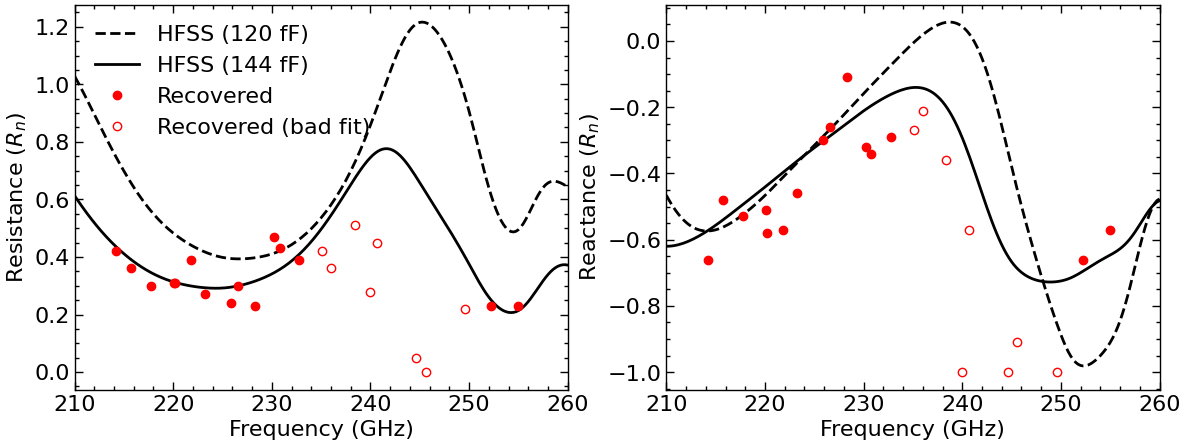

In [8]:
f = np.linspace(210e9, 260e9, 201)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for a, part, label in zip(ax, (np.real, np.imag), ('Resistance', 'Reactance')):
    a.plot(f / 1e9, part(z_nominal(f)) / dciv.rn, 'k--', label='HFSS ({:.0f} fF)'.format(cap_nominal * 1e15))
    a.plot(f / 1e9, part(z_fit(f)) / dciv.rn, 'k-', label='HFSS ({:.0f} fF)'.format(cap_fit * 1e15))
    a.plot(freq[good], part(zt[good]), 'ro', label='Recovered')
    a.plot(freq[~good], part(zt[~good]), 'o', mfc='none', mec='r', label='Recovered (bad fit)')
    a.set_xlabel('Frequency (GHz)')
    a.set_ylabel(label + r' ($R_n$)')
    a.set_xlim(210, 260)
ax[0].legend();

With the fitted capacitance (~140 fF), the HFSS model follows the recovered impedances much more closely than with the nominal capacitance, also at 252-255 GHz, which were not used in the fit. With the measured normal resistance (14.2 ohms, i.e., an area of ~1.4 um^2 for the nominal resistance-area product of 20 ohm um^2), this corresponds to a specific capacitance of ~100 fF/um^2.

## Sideband impedances in the noise model

``PumpedData.mixer_noise`` simulates the mixer with a small-signal analysis (see Example #3). By default, it uses the recovered embedding impedance at the LO for both sidebands. With ``z_emb``, the sideband impedances are taken from a function of frequency instead, e.g., the HFSS embedding impedance. With ``anchor_lo=True``, this function is shifted so that it matches the recovered impedance at the LO frequency.

In [9]:
params_rf = dict(t_hot=295., t_cold=80.)  # hot/cold load temperatures (K)

with quiet():
    dciv_ex = qmix.exp.DCData(load('example-data/dciv.csv'), load('example-data/dcif.csv'), **params, **params_rf)
    pump = qmix.exp.PumpedData(load('example-data/f230.2_iv.csv'), dciv_ex,
                               load('example-data/f230.2_if-hot.csv'), load('example-data/f230.2_if-cold.csv'),
                               freq=230.2, **params, **params_rf)

cases = [('Recovered impedance', None, False),
         ('HFSS (nominal C)', z_nominal, False),
         ('HFSS (fitted C)', z_fit, False),
         ('HFSS (fitted C), anchored', z_fit, True)]

print("Recovered impedance at 230.2 GHz: {:.2f} Rn\n".format(pump.zt))
print("{:28s} {:>13s} {:>13s} {:>6s} {:>7s} {:>7s}".format('Sideband impedances', 'USB (Rn)', 'LSB (Rn)',
                                                      'G_RF', 'T_RF', 'T_mix'))
results = {}
for name, z_emb, anchor in cases:
    with quiet():
        noise = pump.mixer_noise(f_if=5., temp=5.1, smeared=True, z_emb=z_emb, anchor_lo=anchor)
    results[name] = noise
    t_mix = np.interp(pump.v_best, noise.voltage, noise.t_mix)
    print("{:28s} {:6.2f}{:+5.2f}j {:6.2f}{:+5.2f}j {:6.2f} {:5.1f} K {:5.1f} K".format(
          name, noise.z_usb.real, noise.z_usb.imag, noise.z_lsb.real, noise.z_lsb.imag,
          noise.g_rf, noise.t_rf, t_mix))

Recovered impedance at 230.2 GHz: 0.47-0.32j Rn

Sideband impedances               USB (Rn)      LSB (Rn)   G_RF    T_RF   T_mix
Recovered impedance            0.47-0.32j   0.47-0.32j   0.52  20.9 K   3.6 K
HFSS (nominal C)               0.54-0.00j   0.40-0.31j   0.39  18.6 K   3.6 K
HFSS (fitted C)                0.51-0.14j   0.29-0.32j   0.56  20.4 K   4.1 K
HFSS (fitted C), anchored      0.63-0.25j   0.42-0.43j   0.50  20.5 K   3.6 K


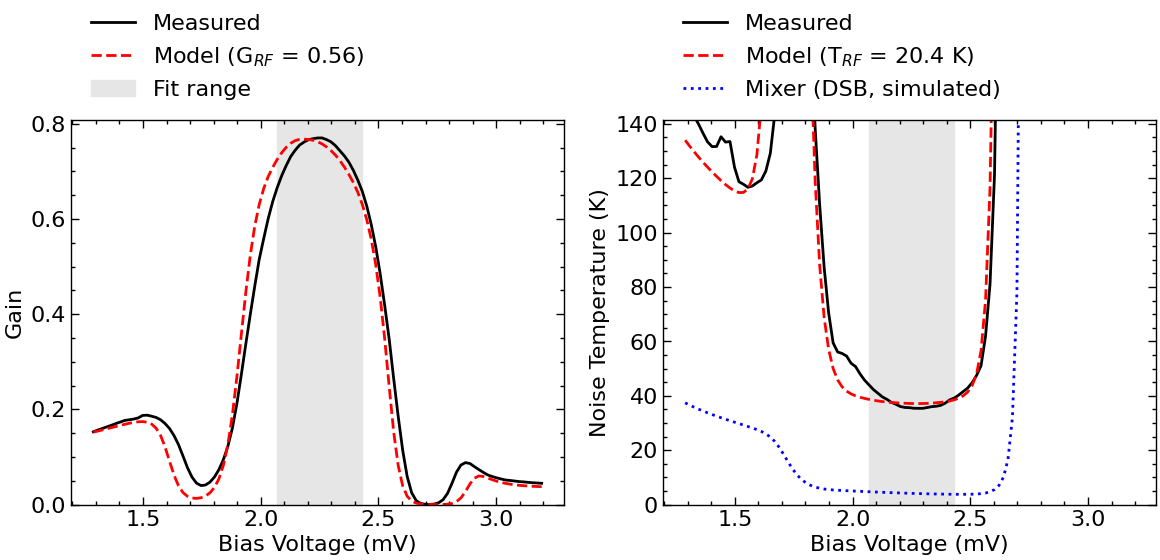

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
pump.plot_mixer_noise(results['HFSS (fitted C)'], ax=ax);

Although the HFSS impedances differ noticeably between the two sidebands, they change mostly the fitted gain of the RF/optics stage (``G_RF``, by up to ~25%), and hardly change its noise (``T_RF``) or the noise of the mixer itself (``T_mix``).

The S-parameters of the RF circuit can also be used to simulate the IF circuit (port 2), but for this mixer, the HFSS IF impedance (with the IF transformer into 50 ohms) is not consistent with the measured gain. The IF circuit is therefore still modelled by a fixed impedance (``z_if``).

## The embedding impedance at the sub-harmonic

Garrett et al. (2019) traced the broken photon steps of this mixer to a spurious harmonic of the LO source at 3/2 f_LO, made worse by the embedding impedance at the sub-harmonic, f_LO / 2. For LO frequencies of 236-255 GHz, the sub-harmonic (118-128 GHz) is below the cutoff frequency of the waveguide (136 GHz). The waveguide port then has an imaginary impedance. ``qmix.network`` connects such ports directly, without renormalizing them, so the embedding impedance can be calculated below cutoff too:

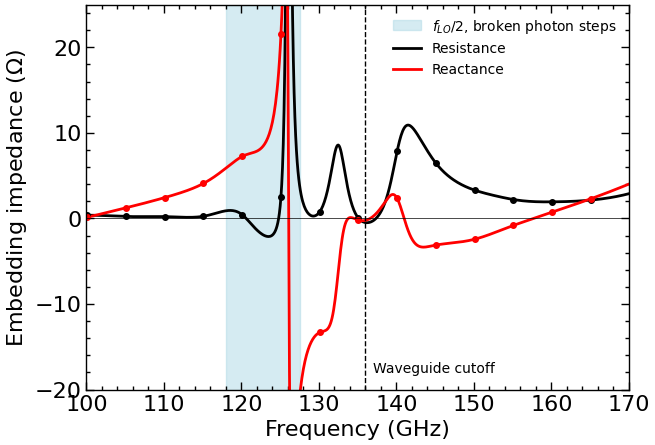

In [11]:
f = np.linspace(100e9, 170e9, 701)
f_grid = rf.freq[(rf.freq >= 100e9) & (rf.freq <= 170e9)]

fig, ax = plt.subplots(figsize=(7, 5))
ax.axvspan(236 / 2, 255 / 2, color='lightblue', alpha=0.5, label='$f_{LO}/2$, broken photon steps')
ax.plot(f / 1e9, z_fit(f).real, 'k-', label='Resistance')
ax.plot(f / 1e9, z_fit(f).imag, 'r-', label='Reactance')
ax.plot(f_grid / 1e9, z_fit(f_grid).real, 'ko', ms=4)
ax.plot(f_grid / 1e9, z_fit(f_grid).imag, 'ro', ms=4)
ax.axvline(136, c='k', ls='--', lw=1)
ax.text(137, -18, 'Waveguide cutoff', fontsize=10)
ax.axhline(0, c='k', lw=0.5)
ax.set_xlabel('Frequency (GHz)')
ax.set_ylabel(r'Embedding impedance ($\Omega$)')
ax.set_xlim(100, 170)
ax.set_ylim(-20, 25)
ax.legend(fontsize=10, loc='upper right');

The embedding impedance is strongly inductive over exactly this range. (The HFSS data are on a 5 GHz grid, shown by the dots, so the shape of the resonance between the grid points is only approximate.) With ``qmix.network``, this impedance can be used directly for a sub-harmonic tone in a multi-tone simulation.

## Simulating the broken photon step

The broken photon step is visible in the pumped I-V curves of this device between ~235 and ~245 GHz: a notch in the first photon step below the gap, followed by a jump at $V_0 = V_\mathrm{gap} - h f_{LO} / 2e$, i.e., half a photon step below the gap. Here, we will simulate the pumped I-V curve at 240.0 GHz, following Garrett et al. (2019).

Since the LO (f_LO), the sub-harmonic (f_LO / 2) and the spurious tone (3/2 f_LO) are all harmonics of f_LO / 2, this only needs one tone with three harmonics:

- p = 1: the sub-harmonic, f_LO / 2. There is no source at this frequency (``vt = 0``), but the junction generates a current here by mixing the LO and the spurious tone. The embedding impedance is from HFSS.
- p = 2: the LO. The embedding impedance is from HFSS.
- p = 3: the spurious tone at 3/2 f_LO = 360 GHz. This is above the frequency range of the HFSS simulations (300 GHz), so the embedding impedance is approximated by the junction capacitance in parallel with a resistance of $R_n$. The capacitance dominates, so the exact resistance hardly matters.

In [12]:
from scipy.optimize import minimize, minimize_scalar
from qmix.circuit import EmbeddingCircuit
from qmix.harmonic_balance import harmonic_balance
from qmix.qtcurrent import qtcurrent

f_lo = 240.0  # GHz
with quiet():
    pump240 = qmix.exp.PumpedData(load('example-data/lo-sweep/f240.0_iv.csv'), dciv, freq=f_lo,
                                  analyze_if=False, **params)

# Embedding impedances (normalized to Rn)
z_sub = z_fit(f_lo / 2 * 1e9) / dciv.rn                    # f_LO / 2, from HFSS
z_lo = z_fit(f_lo * 1e9) / dciv.rn                         # f_LO, from HFSS
w_spur = 2 * np.pi * 1.5 * f_lo * 1e9
z_spur = 1 / (1 + 1j * w_spur * cap_fit * dciv.rn)          # 3/2 f_LO: Rn in parallel with C
print("Embedding impedance (Rn): f_LO/2: {:.2f}, f_LO: {:.2f}, 3/2 f_LO: {:.2f}".format(z_sub, z_lo, z_spur))


def simulate(v, vt_lo, vt_spur, z_sub=z_sub):
    """DC current at bias voltages v, with a spurious tone at 3/2 f_LO."""
    cct = EmbeddingCircuit(1, 3, vb_npts=len(v), vgap=dciv.vgap, rn=dciv.rn)
    cct.vb = v
    cct.freq[1] = pump240.vph / 2              # fundamental frequency: f_LO / 2
    cct.vt[1, 1], cct.zt[1, 1] = 0., z_sub     # p = 1: sub-harmonic (no source)
    cct.vt[1, 2], cct.zt[1, 2] = vt_lo, z_lo   # p = 2: LO
    cct.vt[1, 3], cct.zt[1, 3] = vt_spur, z_spur  # p = 3: spurious tone
    with quiet():
        vj = harmonic_balance(cct, dciv.resp_smear, num_b=30, verbose=False)
    return qtcurrent(vj, cct, dciv.resp_smear, 0., num_b=30, verbose=False).real

Embedding impedance (Rn): f_LO/2: 0.04+0.51j, f_LO: 0.75-0.29j, 3/2 f_LO: 0.04-0.21j


We will fit the Thevenin voltages to the first photon step below the gap: first the LO alone, and then the LO plus the spurious tone. (In this simulation, the phase of the spurious tone relative to the LO hardly changes the DC current, so we take both voltages to be real.)

In [13]:
vph = pump240.vph
v_fit = np.linspace(1 - vph + 0.02, 0.98, 60)
i_meas = np.interp(v_fit, pump240.voltage, pump240.current)


def rms_error(vt_lo, vt_spur, z_sub=z_sub):
    return np.sqrt(np.mean((simulate(v_fit, vt_lo, vt_spur, z_sub) - i_meas) ** 2))


# LO only
fit1 = minimize_scalar(lambda x: rms_error(x, 0.), bounds=(0.2, 1.5), method='bounded')
# LO + spurious tone
fit2 = minimize(lambda x: rms_error(*x), [fit1.x, -0.15], method='Nelder-Mead',
                options=dict(xatol=1e-3, fatol=1e-6))
vt_lo, vt_spur = fit2.x

print("LO only:                 vt = {:.3f}, rms error = {:.4f}".format(fit1.x, fit1.fun))
print("LO + 3/2 f_LO:           vt = {:.3f} and {:.3f}, rms error = {:.4f}".format(vt_lo, vt_spur, fit2.fun))
print("Same, with Z(f_LO/2) = 0: rms error = {:.4f}".format(rms_error(vt_lo, vt_spur, z_sub=0.)))

LO only:                 vt = 0.653, rms error = 0.0177
LO + 3/2 f_LO:           vt = 0.615 and -0.155, rms error = 0.0093
Same, with Z(f_LO/2) = 0: rms error = 0.0139


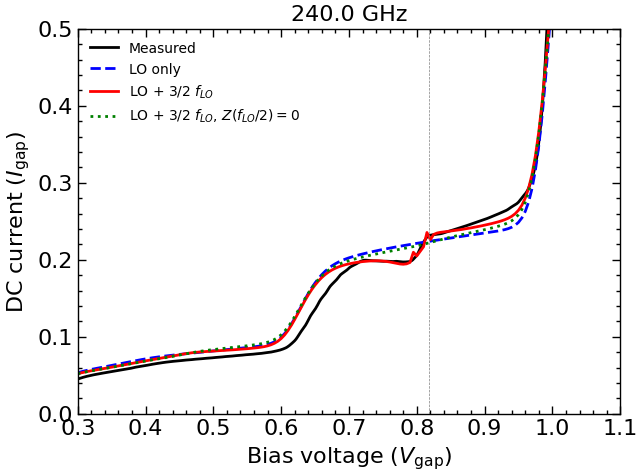

In [14]:
v = np.linspace(0.3, 1.1, 161)
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(pump240.voltage, pump240.current, 'k', label='Measured')
ax.plot(v, simulate(v, fit1.x, 0.), 'b--', label='LO only')
ax.plot(v, simulate(v, vt_lo, vt_spur), 'r', label='LO + 3/2 $f_{LO}$')
ax.plot(v, simulate(v, vt_lo, vt_spur, z_sub=0.), 'g:', label=r'LO + 3/2 $f_{LO}$, $Z(f_{LO}/2) = 0$')
ax.axvline(1 - vph / 2, c='gray', ls='--', lw=0.5)
ax.set_xlabel(r'Bias voltage ($V_\mathrm{gap}$)')
ax.set_ylabel(r'DC current ($I_\mathrm{gap}$)')
ax.set_xlim(0.3, 1.1)
ax.set_ylim(0, 0.5)
ax.set_title('{:.1f} GHz'.format(f_lo))
ax.legend(fontsize=10);

With the LO alone, the simulated photon step is smooth. Adding the spurious tone at 3/2 f_LO halves the error and reproduces the notch and the jump at half a photon step below the gap (gray line). The sub-harmonic embedding impedance is essential: with the same sources but $Z(f_{LO}/2) = 0$, the notch disappears, as in Garrett et al. (2019). The spurious tone and the LO mix to f_LO / 2, and the inductive embedding impedance at this frequency turns this current into a voltage, which creates the extra half-photon steps.

**Note:** At one or two bias voltages right at the jump, the harmonic balance may not converge (the solution changes abruptly there), and QMix prints a warning.